# ES 335 – Machine Learning Project
## Human Activity Recognition from Smartphone Sensor Data (UCI HAR)

| | |
|---|---|
| **Team** | Bhanavath Charan Tej Naik (25110073) · Prashant (25110245) |
| **Course** | ES 335 – Machine Learning (2026) |
| **Dataset** | UCI HAR Dataset (Anguita et al., 2013) |

### Research question
> Given a **2.56-second window** of accelerometer and gyroscope measurements from a smartphone worn at the waist, can we reliably classify which of **six activities** a **new, unseen person** is doing?

**Activities:** WALKING · WALKING_UPSTAIRS · WALKING_DOWNSTAIRS · SITTING · STANDING · LAYING

**Unit of prediction:** one window (128 readings at 50 Hz, 50 % overlap with the next window).
**Target:** activity label (6 classes). **Prediction time:** at the end of the window; only the 561 features computed from that window are used.
**Scope of the claim:** lab recordings of 30 adults (19–48) with one phone model, so we can only claim generalisation to *new people in the same setting*, not to free-living use.

## Step 0 – Imports and setup

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupKFold, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
SEED = 42
np.random.seed(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

os.makedirs("results", exist_ok=True)
os.makedirs("docs/data", exist_ok=True)   # GitHub Pages serves the website from /docs
print("Setup done")

Setup done


## Step 1 – Load the data

The dataset ships with a **subject-disjoint split**: 21 people in train, 9 different people in test. We keep it exactly as given.

In [2]:
# The zip extracts to either "UCI HAR Dataset/" or "UCI HAR Dataset/UCI HAR Dataset/"
for cand in [os.path.join("UCI HAR Dataset", "UCI HAR Dataset"), "UCI HAR Dataset"]:
    if os.path.exists(os.path.join(cand, "features.txt")):
        DATA_DIR = cand
        break
else:
    raise FileNotFoundError("Download the UCI HAR Dataset and unzip it next to this notebook")

def load_split(split):
    p = os.path.join(DATA_DIR, split)
    X = pd.read_csv(os.path.join(p, f"X_{split}.txt"), sep=r"\s+", header=None)
    y = pd.read_csv(os.path.join(p, f"y_{split}.txt"), header=None)[0]
    s = pd.read_csv(os.path.join(p, f"subject_{split}.txt"), header=None)[0]
    return X, y, s

raw_names = pd.read_csv(os.path.join(DATA_DIR, "features.txt"), sep=r"\s+", header=None)[1].tolist()
seen, feature_names = {}, []
for f in raw_names:                     # some names (the bandsEnergy features) repeat in features.txt -> add a suffix
    if f in seen:
        seen[f] += 1; feature_names.append(f"{f}_{seen[f]}")
    else:
        seen[f] = 0; feature_names.append(f)
n_dup = sum(v > 0 for v in seen.values())

ACTIVITY_MAP = {1: "WALKING", 2: "WALKING_UPSTAIRS", 3: "WALKING_DOWNSTAIRS",
                4: "SITTING", 5: "STANDING", 6: "LAYING"}
ACTIVITY_LABELS = [ACTIVITY_MAP[i] for i in range(1, 7)]   # fixed order used everywhere below
SHORT = ["WALK", "UP", "DOWN", "SIT", "STAND", "LAY"]
COLORS = ["#2b6cb0", "#38a1c9", "#6b46c1", "#d53f8c", "#dd6b20", "#2f855a"]

X_train, y_train_raw, subj_train = load_split("train")
X_test,  y_test_raw,  subj_test  = load_split("test")
X_train.columns = feature_names; X_test.columns = feature_names
y_train = y_train_raw.map(ACTIVITY_MAP).values
y_test  = y_test_raw.map(ACTIVITY_MAP).values
groups  = subj_train.values

print(f"Train: {X_train.shape[0]:,} windows x {X_train.shape[1]} features, {subj_train.nunique()} subjects")
print(f"Test : {X_test.shape[0]:,} windows x {X_test.shape[1]} features, {subj_test.nunique()} subjects")
print(f"Train subjects: {sorted(int(s) for s in subj_train.unique())}")
print(f"Test subjects : {sorted(int(s) for s in subj_test.unique())}")
print(f"Subjects in both: {set(subj_train) & set(subj_test)} (must be empty)")
print(f"Distinct feature names that appear more than once: {n_dup} (renamed with _1, _2 suffixes)")

Train: 7,352 windows x 561 features, 21 subjects
Test : 2,947 windows x 561 features, 9 subjects
Train subjects: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
Test subjects : [2, 4, 9, 10, 12, 13, 18, 20, 24]
Subjects in both: set() (must be empty)
Distinct feature names that appear more than once: 42 (renamed with _1, _2 suffixes)


## Step 2 – Understanding the data
### 2a. Class balance (train and test)

,train,test,train %,test %
WALKING,1226,496,16.7,16.8
WALKING_UPSTAIRS,1073,471,14.6,16.0
WALKING_DOWNSTAIRS,986,420,13.4,14.3
SITTING,1286,491,17.5,16.7
STANDING,1374,532,18.7,18.1
LAYING,1407,537,19.1,18.2


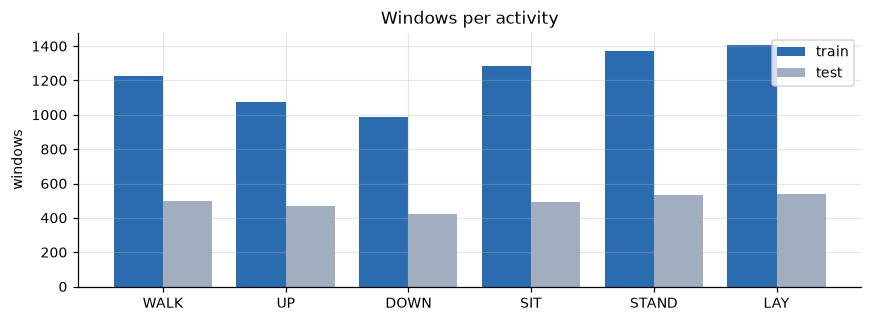

Largest/smallest class ratio (train): 1.43
Classes are close to balanced, but macro-F1 still weights every activity equally, so we use it as the main metric.


In [3]:
train_counts = pd.Series(y_train).value_counts().reindex(ACTIVITY_LABELS)
test_counts  = pd.Series(y_test).value_counts().reindex(ACTIVITY_LABELS)
counts = pd.DataFrame({"train": train_counts, "test": test_counts})
counts["train %"] = (counts["train"] / counts["train"].sum() * 100).round(1)
counts["test %"]  = (counts["test"] / counts["test"].sum() * 100).round(1)
display(counts)

fig, ax = plt.subplots(figsize=(8, 3))
xx = np.arange(6)
ax.bar(xx - 0.2, counts["train"], 0.4, label="train", color="#2b6cb0")
ax.bar(xx + 0.2, counts["test"], 0.4, label="test", color="#a0aec0")
ax.set_xticks(xx); ax.set_xticklabels(SHORT); ax.set_ylabel("windows"); ax.legend()
ax.set_title("Windows per activity")
plt.tight_layout(); plt.savefig("results/01_class_distribution.png", dpi=150); plt.show()
print(f"Largest/smallest class ratio (train): {train_counts.max()/train_counts.min():.2f}")
print("Classes are close to balanced, but macro-F1 still weights every activity equally, so we use it as the main metric.")

### 2b. Data quality and structure

In [4]:
print(f"Missing values: train {int(X_train.isnull().sum().sum())}, test {int(X_test.isnull().sum().sum())}")
print(f"Value range: [{X_train.values.min():.2f}, {X_train.values.max():.2f}]  (the dataset authors already scaled every feature to [-1, 1])")
w = subj_train.value_counts()
print(f"Windows per training subject: min {w.min()}, median {int(w.median())}, max {w.max()}")
corr = np.corrcoef(X_train.values, rowvar=False)
iu = np.triu_indices_from(corr, 1)
print(f"Feature pairs with |correlation| > 0.95: {(np.abs(corr[iu]) > 0.95).sum():,} of {len(iu[0]):,}")
print("\nTwo things matter for evaluation:")
print(" 1. Consecutive windows overlap by 50 %, and each person contributes ~300-400 windows.")
print("    Windows from the same person are therefore NOT independent -> validation must be split by subject.")
print(" 2. Many features are near-duplicates -> per-feature importance scores will be spread across correlated copies.")

Missing values: train 0, test 0
Value range: [-1.00, 1.00]  (the dataset authors already scaled every feature to [-1, 1])
Windows per training subject: min 281, median 347, max 409


Feature pairs with |correlation| > 0.95: 2,281 of 157,080

Two things matter for evaluation:
 1. Consecutive windows overlap by 50 %, and each person contributes ~300-400 windows.
    Windows from the same person are therefore NOT independent -> validation must be split by subject.
 2. Many features are near-duplicates -> per-feature importance scores will be spread across correlated copies.


### 2c. PCA projection (fit on training data only)

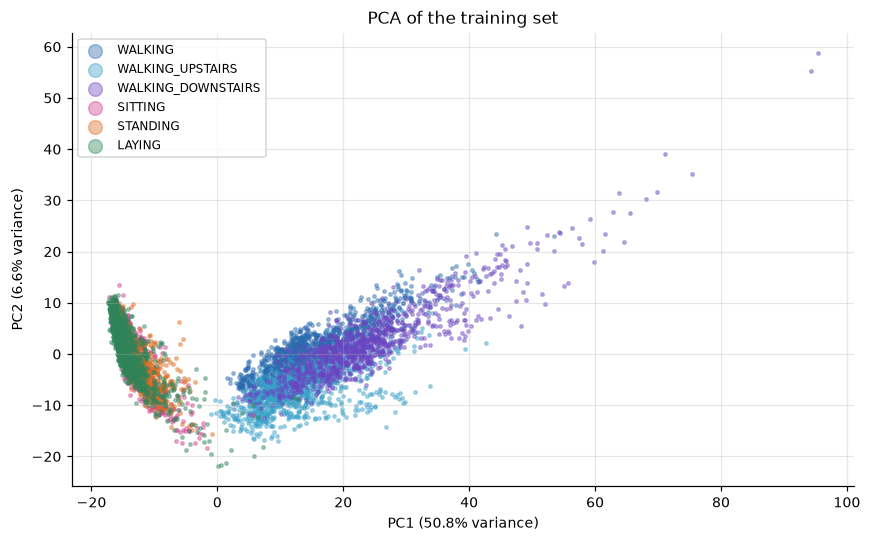

PC1 + PC2 explain 57.4% of variance.
Moving activities separate from still ones along PC1; SITTING and STANDING overlap heavily even here.


In [5]:
pca_pipe = Pipeline([("scale", StandardScaler()), ("pca", PCA(n_components=2, random_state=SEED))])
X_pca = pca_pipe.fit_transform(X_train)
evr = pca_pipe.named_steps["pca"].explained_variance_ratio_

fig, ax = plt.subplots(figsize=(8, 5))
for act, col in zip(ACTIVITY_LABELS, COLORS):
    m = y_train == act
    ax.scatter(X_pca[m, 0], X_pca[m, 1], s=5, alpha=0.4, color=col, label=act)
ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}% variance)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}% variance)")
ax.legend(markerscale=4, fontsize=8); ax.set_title("PCA of the training set")
plt.tight_layout(); plt.savefig("results/02_pca_visualization.png", dpi=150); plt.show()
print(f"PC1 + PC2 explain {evr.sum()*100:.1f}% of variance.")
print("Moving activities separate from still ones along PC1; SITTING and STANDING overlap heavily even here.")

## Step 3 – Preprocessing and evaluation design (fixed before any model is compared)

| Decision | Why |
|---|---|
| Keep the given subject-disjoint train/test split | The question is about *new people*; the test set is touched once at the end |
| **GroupKFold (5 folds) grouped by subject** for all tuning and model selection | Overlapping windows from one person are near-copies; a random K-fold would put the same person in train and validation and inflate scores |
| Scaling inside a `Pipeline` | The scaler is re-fit on the training part of every CV fold, so no validation or test statistics leak into preprocessing |
| No imputation | No missing values |
| Select the final model by **CV macro-F1**, not test score | Choosing by test score would turn the test set into a validation set |

**Metric:** macro-F1 (mean of per-class F1). It punishes a model that ignores any single activity. Accuracy is reported alongside it.

**Known limitation we cannot fix:** the dataset authors scaled the features to [-1, 1] before splitting, probably using all the data. This is mild (a fixed linear rescale), but it is preprocessing we did not fit on training data only.

In [6]:
gkf = GroupKFold(n_splits=5)
for i, (tr, va) in enumerate(gkf.split(X_train, y_train, groups)):
    print(f"Fold {i+1}: validation subjects {sorted(int(s) for s in set(groups[va]))}")

Fold 1: validation subjects [14, 15, 19, 25]
Fold 2: validation subjects [6, 16, 21, 22]
Fold 3: validation subjects [3, 11, 17, 26]
Fold 4: validation subjects [1, 7, 23, 30]
Fold 5: validation subjects [5, 8, 27, 28, 29]


## Step 4 – Baseline and models, tuned with subject-grouped CV

| Model | Objective / core idea | Main assumptions | Why it fits here | Grid searched |
|---|---|---|---|---|
| Majority class | Predict the most frequent training class | None | Lower bound any real model must beat | – |
| Logistic Regression | Minimise L2-regularised cross-entropy (softmax over 6 classes) | Class log-odds are linear in the features | Interpretable baseline: are the engineered features linearly separable? | C |
| Random Forest | Average many trees, each grown greedily to reduce Gini impurity on a bootstrap sample with random feature subsets | Classes separable by axis-aligned thresholds; trees' errors partly independent | Handles redundant features and non-linear thresholds; no scaling needed | max_features, min_samples_leaf |
| SVM (RBF kernel) | Maximise the margin between classes (hinge loss + L2 penalty) in the space implied by the RBF kernel | Nearby points (in scaled Euclidean distance) tend to share a class; features on comparable scales | Smooth non-linear boundary; the method used in the original dataset paper | C, gamma |
| k-NN | Majority vote of the k closest training windows | Euclidean distance on scaled features is meaningful in 561 dimensions | No training; tests whether "nearby" means "same activity" across people | k, weighting |

All five treat windows as independent samples. They are not (overlap, same person), which is exactly why validation and the uncertainty estimate below are done per person.

In [7]:
def pipe(model, scale=True):
    return Pipeline(([("scale", StandardScaler())] if scale else []) + [("model", model)])

search_space = {
    "Majority Class (Baseline)": (pipe(DummyClassifier(strategy="most_frequent"), scale=False), {}),
    "Logistic Regression": (pipe(LogisticRegression(max_iter=3000, random_state=SEED)),
                            {"model__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (pipe(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1), scale=False),
                      {"model__max_features": ["sqrt", 0.1], "model__min_samples_leaf": [1, 5]}),
    "SVM (RBF)": (pipe(SVC(kernel="rbf", random_state=SEED)),
                  {"model__C": [1, 10, 100], "model__gamma": ["scale", 1e-3, 1e-4]}),
    "k-Nearest Neighbours": (pipe(KNeighborsClassifier()),
                             {"model__n_neighbors": [5, 11, 21, 41], "model__weights": ["uniform", "distance"]}),
}

fitted, rows, searches = {}, [], {}
for name, (est, grid) in search_space.items():
    gs = GridSearchCV(est, grid or {"model__strategy": ["most_frequent"]}, cv=gkf,
                      scoring="f1_macro", n_jobs=-1, refit=True)
    gs.fit(X_train, y_train, groups=groups)
    i = gs.best_index_
    fold_scores = [gs.cv_results_[f"split{k}_test_score"][i] for k in range(5)]
    fitted[name] = gs.best_estimator_
    searches[name] = gs
    params = {k.replace("model__", ""): v for k, v in gs.best_params_.items() if k != "model__strategy"}
    rows.append({"Model": name, "Best params": params,
                 "CV Macro-F1 (mean)": np.mean(fold_scores), "CV Macro-F1 (std)": np.std(fold_scores)})
    print(f"{name:27s} CV macro-F1 = {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}   best {params}")

results_df = pd.DataFrame(rows)
selected = results_df.loc[results_df["CV Macro-F1 (mean)"].idxmax(), "Model"]
print(f"\nSelected by CV (before looking at test): {selected}")

Majority Class (Baseline)   CV macro-F1 = 0.0535 ± 0.0025   best {}


Logistic Regression         CV macro-F1 = 0.9339 ± 0.0427   best {'C': 0.1}


Random Forest               CV macro-F1 = 0.9176 ± 0.0435   best {'max_features': 'sqrt', 'min_samples_leaf': 5}


SVM (RBF)                   CV macro-F1 = 0.9322 ± 0.0455   best {'C': 100, 'gamma': 0.0001}


k-Nearest Neighbours        CV macro-F1 = 0.8729 ± 0.0328   best {'n_neighbors': 21, 'weights': 'distance'}

Selected by CV (before looking at test): Logistic Regression


### 4a. Full grid-search results
Every setting tried for every model, with its score on each of the 5 person-grouped folds, so the tuning above can be checked. Saved to `results/grid_search_results.csv`.

In [8]:
grid_rows = []
for name, gs in searches.items():
    cvr = gs.cv_results_
    for i, params in enumerate(cvr["params"]):
        grid_rows.append({
            "Model": name,
            "Params": str({k.replace("model__", ""): v for k, v in params.items() if k != "model__strategy"}),
            "CV Macro-F1 (mean)": cvr["mean_test_score"][i],
            "CV Macro-F1 (std)": cvr["std_test_score"][i],
            **{f"Fold {k+1}": cvr[f"split{k}_test_score"][i] for k in range(5)},
            "Rank within model": int(cvr["rank_test_score"][i]),
        })
grid_df = pd.DataFrame(grid_rows)
grid_df.to_csv("results/grid_search_results.csv", index=False)
display(grid_df[["Model", "Params", "CV Macro-F1 (mean)", "CV Macro-F1 (std)", "Rank within model"]].round(4))
print(f"Wrote results/grid_search_results.csv ({len(grid_df)} settings)")


,Model,Params,CV Macro-F1 (mean),CV Macro-F1 (std),Rank within model
0,Majority Class (Baseline),{},0.0535,0.0025,1
1,Logistic Regression,{'C': 0.01},0.9279,0.0483,4
2,Logistic Regression,{'C': 0.1},0.9339,0.0427,1
3,Logistic Regression,{'C': 1},0.9334,0.0420,2
4,Logistic Regression,{'C': 10},0.9286,0.0426,3
5,Random Forest,"{'max_features': 'sqrt', 'min_samples_leaf': 1}",0.9163,0.0455,3
6,Random Forest,"{'max_features': 'sqrt', 'min_samples_leaf': 5}",0.9176,0.0435,1
7,Random Forest,"{'max_features': 0.1, 'min_samples_leaf': 1}",0.9088,0.0507,4
8,Random Forest,"{'max_features': 0.1, 'min_samples_leaf': 5}",0.9165,0.0420,2
9,SVM (RBF),"{'C': 1, 'gamma': 'scale'}",0.9220,0.0445,7


Wrote results/grid_search_results.csv (26 settings)


### 4b. Why grouping by subject matters (quantified)
Same models and settings, scored two ways on the training data. The gap is the optimism you get when the same person appears in both the training and validation folds.

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
leak_rows = []
for name in ["Logistic Regression", "SVM (RBF)", "k-Nearest Neighbours"]:
    est = fitted[name]
    shuffled = cross_val_score(est, X_train, y_train, cv=skf, scoring="f1_macro", n_jobs=-1).mean()
    grouped = results_df.set_index("Model").loc[name, "CV Macro-F1 (mean)"]
    leak_rows.append({"Model": name, "Random window K-fold": round(shuffled, 4),
                      "Subject-grouped K-fold": round(grouped, 4), "Inflation": round(shuffled - grouped, 4)})
leak_df = pd.DataFrame(leak_rows)
display(leak_df)
print("Random window splits overstate performance on new people; the grouped CV numbers are the ones we trust.")

,Model,Random window K-fold,Subject-grouped K-fold,Inflation
0,Logistic Regression,0.9836,0.9339,0.0497
1,SVM (RBF),0.9841,0.9322,0.0519
2,k-Nearest Neighbours,0.9514,0.8729,0.0786


Random window splits overstate performance on new people; the grouped CV numbers are the ones we trust.


## Step 5 – Final test evaluation (test set used once, after selection)

In [10]:
preds = {}
for i, name in enumerate(results_df["Model"]):
    est = fitted[name]
    preds[name] = est.predict(X_test)
    results_df.loc[i, "Train Macro-F1"] = f1_score(y_train, est.predict(X_train), average="macro")
    results_df.loc[i, "Test Macro-F1"] = f1_score(y_test, preds[name], average="macro")
    results_df.loc[i, "Test Accuracy"] = accuracy_score(y_test, preds[name])

show = results_df.copy()
for c in ["CV Macro-F1 (mean)", "CV Macro-F1 (std)", "Train Macro-F1", "Test Macro-F1", "Test Accuracy"]:
    show[c] = show[c].round(4)
display(show)
print(f"Selected model ({selected}): test macro-F1 = {results_df.set_index('Model').loc[selected, 'Test Macro-F1']:.4f}")
print(f"Majority baseline: test macro-F1 = {results_df.set_index('Model').loc['Majority Class (Baseline)', 'Test Macro-F1']:.4f}")

,Model,Best params,CV Macro-F1 (mean),CV Macro-F1 (std),Train Macro-F1,Test Macro-F1,Test Accuracy
0,Majority Class (Baseline),{},0.0535,0.0025,0.0535,0.0514,0.1822
1,Logistic Regression,{'C': 0.1},0.9339,0.0427,0.9912,0.9500,0.9498
2,Random Forest,"{'max_features': 'sqrt', 'min_samples_leaf': 5}",0.9176,0.0435,0.9981,0.9234,0.9257
3,SVM (RBF),"{'C': 100, 'gamma': 0.0001}",0.9322,0.0455,0.9915,0.9561,0.9562
4,k-Nearest Neighbours,"{'n_neighbors': 21, 'weights': 'distance'}",0.8729,0.0328,1.0000,0.8833,0.8870


Selected model (Logistic Regression): test macro-F1 = 0.9500
Majority baseline: test macro-F1 = 0.0514


### 5b. Uncertainty: bootstrap over test subjects
Windows from one person are correlated, so we resample **people**, not windows: draw 9 test subjects with replacement, recompute macro-F1, repeat 2,000 times. With only 9 test subjects these intervals are rough, but they show how much the score depends on *which* people are tested.

**What this can establish:** how stable the test score is across different sets of test people, and whether the LR–SVM gap is larger than that variation. **What it cannot:** it keeps the trained models fixed, so it ignores variation from *which people were used for training*; and with 9 people the interval edges themselves are uncertain. It is not a formal significance test.

In [11]:
rng = np.random.default_rng(SEED)
test_subjects = np.array(sorted(subj_test.unique()))
idx_by_subj = {s: np.where(subj_test.values == s)[0] for s in test_subjects}
B = 2000
boot_draws = [np.concatenate([idx_by_subj[s] for s in rng.choice(test_subjects, len(test_subjects))]) for _ in range(B)]

boot = {}
for name in results_df["Model"]:
    p = preds[name]
    boot[name] = np.array([f1_score(y_test[ix], p[ix], average="macro") for ix in boot_draws])
for i, name in enumerate(results_df["Model"]):
    lo, hi = np.percentile(boot[name], [2.5, 97.5])
    results_df.loc[i, "CI low"], results_df.loc[i, "CI high"] = lo, hi
    print(f"{name:27s} test macro-F1 {results_df.loc[i, 'Test Macro-F1']:.3f}  95% CI [{lo:.3f}, {hi:.3f}]")

# Paired comparison on the same bootstrap draws
runner_up = results_df[results_df["Model"] != selected].sort_values("CV Macro-F1 (mean)").iloc[-1]["Model"]
diff = boot[selected] - boot[runner_up]
d_lo, d_hi = np.percentile(diff, [2.5, 97.5])
print(f"\n{selected} minus {runner_up}: mean {diff.mean():+.3f}, 95% CI [{d_lo:+.3f}, {d_hi:+.3f}]; "
      f"{selected} better in {(diff > 0).mean()*100:.0f}% of resamples")
print("If this interval includes 0, the test data cannot tell the two models apart.")
results_df.to_csv("results/03_model_comparison.csv", index=False)

Majority Class (Baseline)   test macro-F1 0.051  95% CI [0.050, 0.053]
Logistic Regression         test macro-F1 0.950  95% CI [0.915, 0.976]
Random Forest               test macro-F1 0.923  95% CI [0.890, 0.954]
SVM (RBF)                   test macro-F1 0.956  95% CI [0.932, 0.974]
k-Nearest Neighbours        test macro-F1 0.883  95% CI [0.851, 0.911]

Logistic Regression minus SVM (RBF): mean -0.006, 95% CI [-0.021, +0.003]; Logistic Regression better in 19% of resamples
If this interval includes 0, the test data cannot tell the two models apart.


## Step 6 – Confusion matrices and per-class results

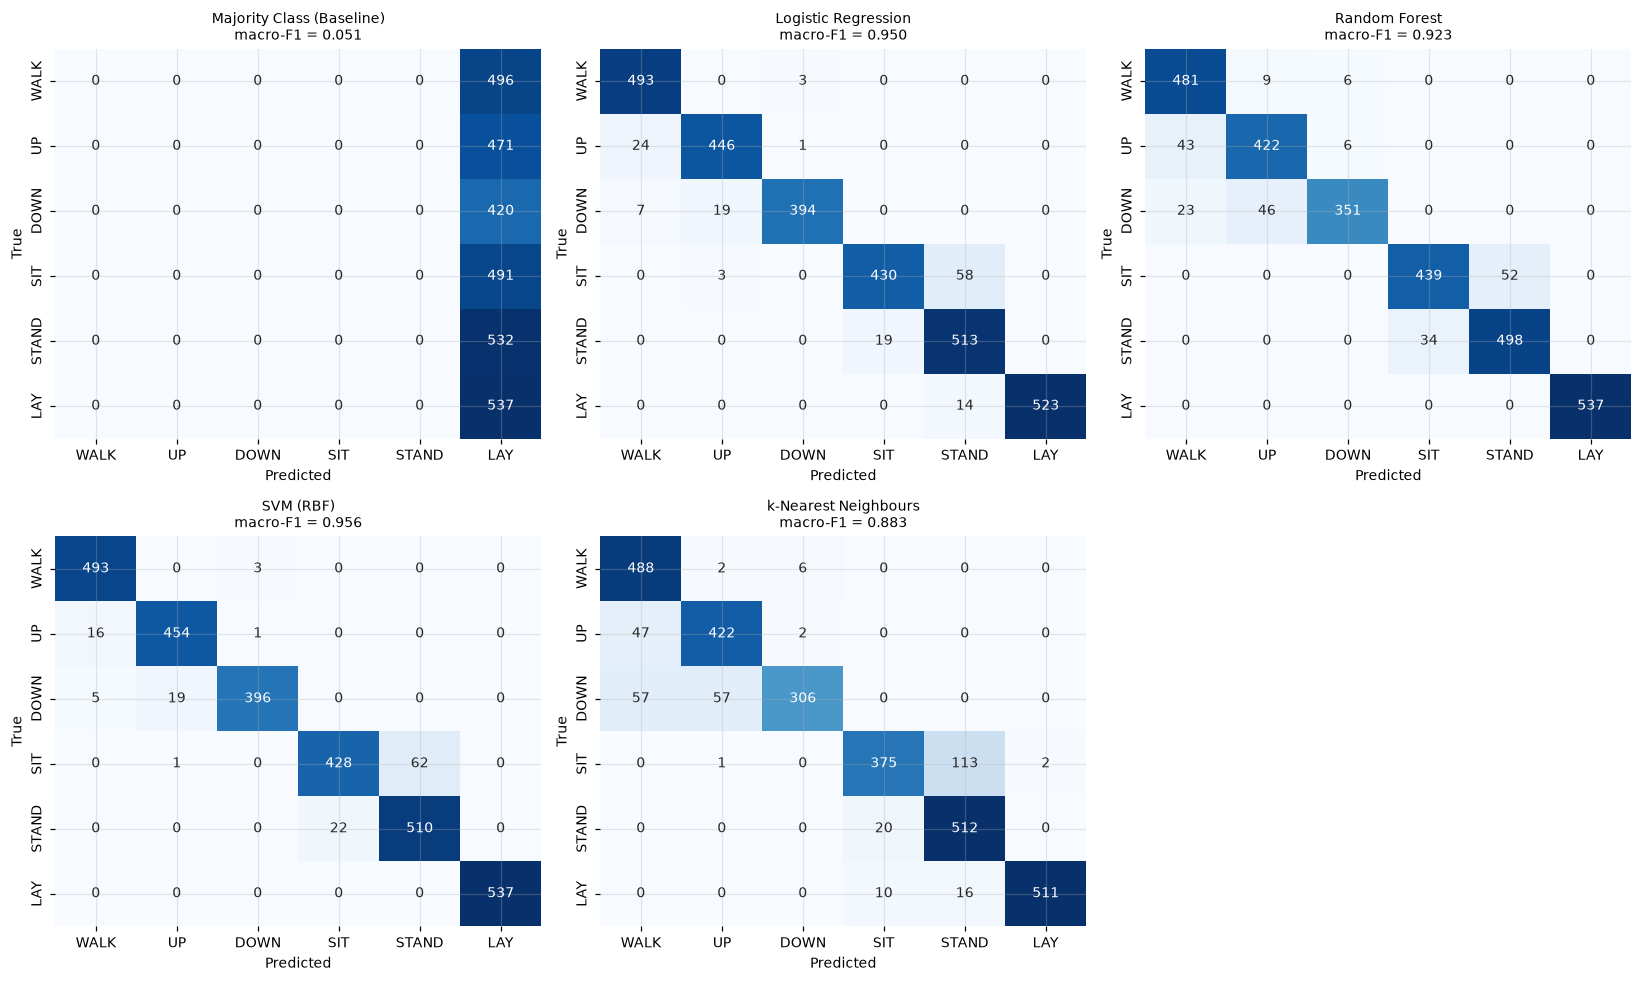

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9)); axes = axes.flatten()
cms = {}
for ax, name in zip(axes, results_df["Model"]):
    cm = confusion_matrix(y_test, preds[name], labels=ACTIVITY_LABELS)   # labels= fixes row/column order
    cms[name] = cm
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=SHORT, yticklabels=SHORT)
    ax.set_title(f"{name}\nmacro-F1 = {f1_score(y_test, preds[name], average='macro'):.3f}", fontsize=9)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
axes[-1].axis("off")
plt.tight_layout(); plt.savefig("results/04_cm_all_models.png", dpi=150); plt.show()

In [13]:
# labels= is required: without it sklearn sorts class names alphabetically and target names get attached to the wrong rows
print(f"Per-class report – {selected}\n")
print(classification_report(y_test, preds[selected], labels=ACTIVITY_LABELS, digits=3))
rep = classification_report(y_test, preds[selected], labels=ACTIVITY_LABELS, output_dict=True)
worst = min(ACTIVITY_LABELS, key=lambda a: rep[a]["f1-score"])
best_c = max(ACTIVITY_LABELS, key=lambda a: rep[a]["f1-score"])
print(f"Easiest class: {best_c} (F1 {rep[best_c]['f1-score']:.3f}); hardest: {worst} (F1 {rep[worst]['f1-score']:.3f})")

Per-class report – Logistic Regression

                    precision    recall  f1-score   support

           WALKING      0.941     0.994     0.967       496
  WALKING_UPSTAIRS      0.953     0.947     0.950       471
WALKING_DOWNSTAIRS      0.990     0.938     0.963       420
           SITTING      0.958     0.876     0.915       491
          STANDING      0.877     0.964     0.919       532
            LAYING      1.000     0.974     0.987       537

          accuracy                          0.950      2947
         macro avg      0.953     0.949     0.950      2947
      weighted avg      0.952     0.950     0.950      2947

Easiest class: LAYING (F1 0.987); hardest: SITTING (F1 0.915)


## Step 7 – Error analysis
### 7a. Which mistakes, and who makes them?

In [14]:
cm = cms[selected]
pairs = [(ACTIVITY_LABELS[i], ACTIVITY_LABELS[j], int(cm[i, j])) for i in range(6) for j in range(6) if i != j and cm[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
n_err = int((preds[selected] != y_test).sum())
print(f"{selected}: {n_err} errors out of {len(y_test)} test windows\n")
for t, p, n in pairs[:6]:
    print(f"  true {t:19s} -> predicted {p:19s} {n:4d}  ({n/n_err*100:.0f}% of all errors)")

err_mask = preds[selected] != y_test
sit_stand = ((y_test == "SITTING") & (preds[selected] == "STANDING")) | ((y_test == "STANDING") & (preds[selected] == "SITTING"))
by_subj = pd.DataFrame({"subject": subj_test.values, "error": err_mask, "sit_stand": sit_stand}).groupby("subject").sum()
by_subj["share of sit/stand errors"] = (by_subj["sit_stand"] / by_subj["sit_stand"].sum() * 100).round(0)
display(by_subj.sort_values("error", ascending=False))
top2 = by_subj.sort_values("sit_stand", ascending=False).head(2)
print(f"Subjects {list(top2.index)} account for {top2['sit_stand'].sum()/by_subj['sit_stand'].sum()*100:.0f}% "
      "of SITTING/STANDING confusions -> errors are concentrated in a few people, not spread evenly.")

Logistic Regression: 148 errors out of 2947 test windows

  true SITTING             -> predicted STANDING              58  (39% of all errors)
  true WALKING_UPSTAIRS    -> predicted WALKING               24  (16% of all errors)
  true WALKING_DOWNSTAIRS  -> predicted WALKING_UPSTAIRS      19  (13% of all errors)
  true STANDING            -> predicted SITTING               19  (13% of all errors)
  true LAYING              -> predicted STANDING              14  (9% of all errors)
  true WALKING_DOWNSTAIRS  -> predicted WALKING                7  (5% of all errors)


,error,sit_stand,share of sit/stand errors
subject,,,
10,51,22,29.0
9,30,19,25.0
20,17,7,9.0
12,15,11,14.0
4,14,10,13.0
18,11,2,3.0
2,5,5,6.0
13,4,0,0.0
24,1,1,1.0


Subjects [10, 9] account for 53% of SITTING/STANDING confusions -> errors are concentrated in a few people, not spread evenly.


### 7b. Representative errors: what does a misclassified SITTING window look like?
We pick the single feature that best separates SITTING from STANDING **in the training data** (largest standardised mean difference), then compare where correctly and wrongly classified test windows fall on it.

Most SIT/STAND-separating feature on train: tGravityAcc-max()-Y (standardised difference 2.04)
Next four: tGravityAcc-mean()-Y, angle(Y,gravityMean), tGravityAcc-min()-Y, fBodyGyro-meanFreq()-X


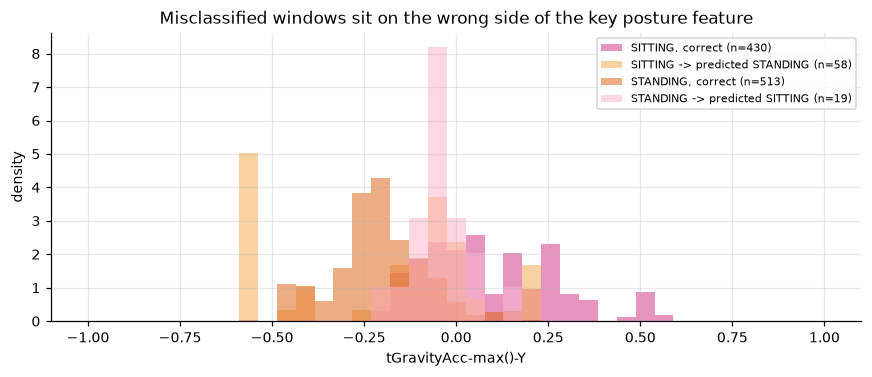

  median tGravityAcc-max()-Y — SITTING, correct              : +0.058
  median tGravityAcc-max()-Y — SITTING -> predicted STANDING : -0.105
  median tGravityAcc-max()-Y — STANDING, correct             : -0.214
  median tGravityAcc-max()-Y — STANDING -> predicted SITTING : -0.062

Midpoint between the two correct groups: -0.078
SITTING->STANDING errors fall on the STANDING side of the midpoint: True
STANDING->SITTING errors fall on the SITTING side of the midpoint: True
So the errors are windows whose phone orientation looks like the other posture. The Y-axis gravity component
reflects how the phone is tilted; a person who sits very upright (or wears the phone differently) can look like
they are standing. We cannot confirm the cause from this data, only that the errors sit in the overlap region.


,test row,subject,tGravityAcc-max()-Y
0,42,2,-0.141
5,508,4,-0.001
10,786,9,0.028
19,1077,10,-0.573
39,1240,12,-0.058


In [15]:
sit_tr, stand_tr = X_train[y_train == "SITTING"], X_train[y_train == "STANDING"]
pooled = np.sqrt((sit_tr.var() + stand_tr.var()) / 2)
effect = ((sit_tr.mean() - stand_tr.mean()) / pooled).abs().sort_values(ascending=False)
key_feat = effect.index[0]
print(f"Most SIT/STAND-separating feature on train: {key_feat} (standardised difference {effect.iloc[0]:.2f})")
print("Next four:", ", ".join(effect.index[1:5]))

grp = {
    "SITTING, correct":          (y_test == "SITTING") & (preds[selected] == "SITTING"),
    "SITTING -> predicted STANDING": (y_test == "SITTING") & (preds[selected] == "STANDING"),
    "STANDING, correct":         (y_test == "STANDING") & (preds[selected] == "STANDING"),
    "STANDING -> predicted SITTING": (y_test == "STANDING") & (preds[selected] == "SITTING"),
}
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(X_test[key_feat].min(), X_test[key_feat].max(), 40)
for (lbl, m), col in zip(grp.items(), ["#d53f8c", "#f6ad55", "#dd6b20", "#fbb6ce"]):
    ax.hist(X_test.loc[m, key_feat], bins=bins, alpha=0.55, label=f"{lbl} (n={m.sum()})", color=col, density=True)
ax.set_xlabel(key_feat); ax.set_ylabel("density"); ax.legend(fontsize=7)
ax.set_title("Misclassified windows sit on the wrong side of the key posture feature")
plt.tight_layout(); plt.savefig("results/07_error_feature.png", dpi=150); plt.show()
med = {lbl: float(X_test.loc[m, key_feat].median()) for lbl, m in grp.items()}
for k, v in med.items():
    print(f"  median {key_feat} — {k:30s}: {v:+.3f}")
mid = (med["SITTING, correct"] + med["STANDING, correct"]) / 2
print(f"\nMidpoint between the two correct groups: {mid:+.3f}")
print(f"SITTING->STANDING errors fall on the STANDING side of the midpoint: {med['SITTING -> predicted STANDING'] < mid}")
print(f"STANDING->SITTING errors fall on the SITTING side of the midpoint: {med['STANDING -> predicted SITTING'] > mid}")
print("So the errors are windows whose phone orientation looks like the other posture. The Y-axis gravity component")
print("reflects how the phone is tilted; a person who sits very upright (or wears the phone differently) can look like")
print("they are standing. We cannot confirm the cause from this data, only that the errors sit in the overlap region.")

# A few concrete examples
ex_idx = np.where(grp["SITTING -> predicted STANDING"])[0]
ex = pd.DataFrame({"test row": ex_idx, "subject": subj_test.values[ex_idx],
                   key_feat: X_test[key_feat].values[ex_idx].round(3)})
ex = ex.groupby("subject").head(1).head(5)
display(ex)

### 7c. Per-subject performance

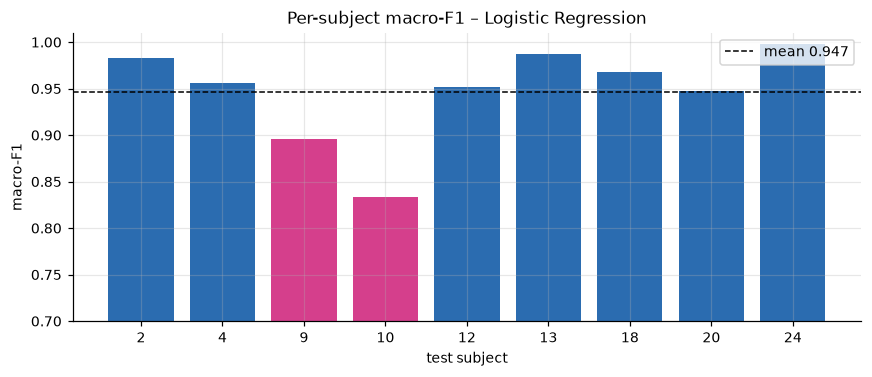

,Subject,Windows,Accuracy,Macro-F1
0,2,302,0.9834,0.9830
1,4,317,0.9558,0.9559
2,9,288,0.8958,0.8954
3,10,294,0.8265,0.8340
4,12,320,0.9531,0.9521
5,13,327,0.9878,0.9869
6,18,364,0.9698,0.9679
7,20,354,0.9520,0.9474
8,24,381,0.9974,0.9976


Range across people: 0.834 (subject 10) to 0.998 (subject 24)


In [16]:
subj_rows = []
for s in test_subjects:
    m = subj_test.values == s
    subj_rows.append({"Subject": int(s), "Windows": int(m.sum()),
                      "Accuracy": accuracy_score(y_test[m], preds[selected][m]),
                      "Macro-F1": f1_score(y_test[m], preds[selected][m], average="macro")})
subj_df = pd.DataFrame(subj_rows)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(subj_df["Subject"].astype(str), subj_df["Macro-F1"], color=["#d53f8c" if v < 0.9 else "#2b6cb0" for v in subj_df["Macro-F1"]])
ax.axhline(subj_df["Macro-F1"].mean(), ls="--", color="k", lw=1, label=f"mean {subj_df['Macro-F1'].mean():.3f}")
ax.set_ylim(0.7, 1.01); ax.set_xlabel("test subject"); ax.set_ylabel("macro-F1"); ax.legend()
ax.set_title(f"Per-subject macro-F1 – {selected}")
plt.tight_layout(); plt.savefig("results/06_per_subject_accuracy.png", dpi=150); plt.show()
display(subj_df.round(4))
print(f"Range across people: {subj_df['Macro-F1'].min():.3f} (subject {subj_df.loc[subj_df['Macro-F1'].idxmin(), 'Subject']}) "
      f"to {subj_df['Macro-F1'].max():.3f} (subject {subj_df.loc[subj_df['Macro-F1'].idxmax(), 'Subject']})")

## Step 8 – Which features does the model rely on?
Caveat: many features are near-duplicates (Step 2b), so importance is split across correlated copies. We therefore also sum importance by **signal group**, which is more trustworthy than individual ranks. This shows association with the label in this dataset, not causation.

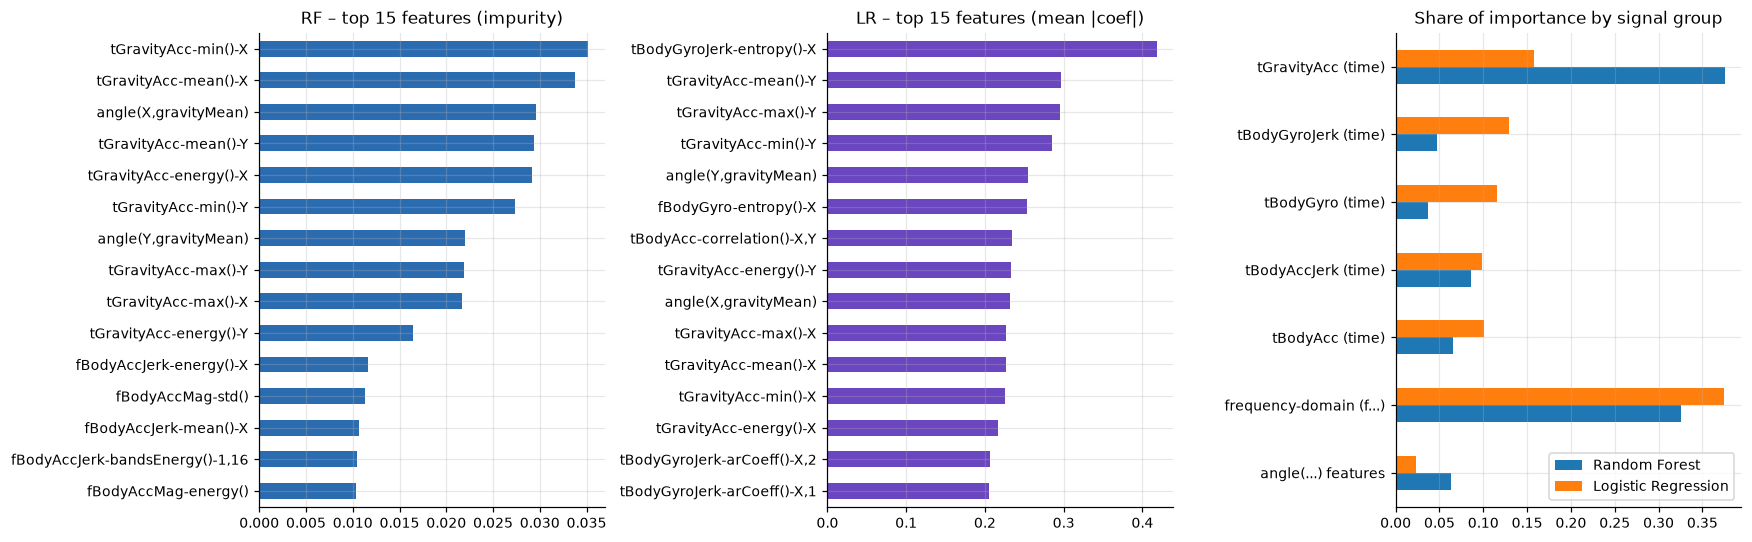

Random Forest – importance share by group:
tGravityAcc (time)         0.376
frequency-domain (f...)    0.326
tBodyAccJerk (time)        0.086
tBodyAcc (time)            0.065
angle(...) features        0.063
tBodyGyroJerk (time)       0.048
tBodyGyro (time)           0.037

RF top-10 features from tGravityAcc or angle(): 10/10
-> Gravity direction (phone orientation) dominates. It separates LAYING from upright postures and is the main SITTING/STANDING cue.
   Frequency-domain features carry most of the remaining importance (we did not test which classes they help most).


In [17]:
rf = fitted["Random Forest"].named_steps["model"]
lr = fitted["Logistic Regression"].named_steps["model"]
rf_imp = pd.Series(rf.feature_importances_, index=feature_names)
lr_imp = pd.Series(np.abs(lr.coef_).mean(axis=0), index=feature_names)   # features are standardised, so |coef| is comparable

def signal_group(f):
    if f.startswith("angle"): return "angle(...) features"
    base = f.split("-")[0]
    for g in ["tGravityAcc", "tBodyAccJerk", "tBodyAcc", "tBodyGyroJerk", "tBodyGyro"]:
        if base.startswith(g): return g + " (time)"
    return "frequency-domain (f...)"

grp_rf = rf_imp.groupby(rf_imp.index.map(signal_group)).sum().sort_values(ascending=False)
grp_lr = (lr_imp / lr_imp.sum()).groupby(lr_imp.index.map(signal_group)).sum().sort_values(ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
top_rf = rf_imp.nlargest(15)[::-1]; top_rf.plot.barh(ax=axes[0], color="#2b6cb0"); axes[0].set_title("RF – top 15 features (impurity)")
top_lr = lr_imp.nlargest(15)[::-1]; top_lr.plot.barh(ax=axes[1], color="#6b46c1"); axes[1].set_title("LR – top 15 features (mean |coef|)")
pd.DataFrame({"Random Forest": grp_rf, "Logistic Regression": grp_lr}).plot.barh(ax=axes[2]); axes[2].set_title("Share of importance by signal group")
plt.tight_layout(); plt.savefig("results/05_feature_importance.png", dpi=150); plt.show()
print("Random Forest – importance share by group:"); print(grp_rf.round(3).to_string())
print(f"\nRF top-10 features from tGravityAcc or angle(): {sum(signal_group(f) in ['tGravityAcc (time)', 'angle(...) features'] for f in rf_imp.nlargest(10).index)}/10")
print("-> Gravity direction (phone orientation) dominates. It separates LAYING from upright postures and is the main SITTING/STANDING cue.")
print("   Frequency-domain features carry most of the remaining importance (we did not test which classes they help most).")

## Step 9 – A small, real model for the website demo
The website lets visitors move sliders and see a prediction. To make that honest, the demo runs a **real logistic regression** trained on 8 interpretable features (chosen by hand for meaning: movement intensity, phone orientation, rotation, frequency). Its weights are exported to JSON and the browser does the same arithmetic. It is tuned with the same grouped CV and scored once on the test set, so visitors can see how much the full 561-feature model gains.

In [18]:
DEMO_FEATURES = ["tBodyAcc-std()-X", "tBodyAccMag-mean()", "tGravityAcc-mean()-X", "tGravityAcc-mean()-Y",
                 "tGravityAcc-mean()-Z", "tBodyAccJerk-std()-Z", "tBodyGyro-std()-Y", "fBodyAccMag-meanFreq()"]
demo_gs = GridSearchCV(pipe(LogisticRegression(max_iter=3000, random_state=SEED)), {"model__C": [0.1, 1, 10, 100]},
                       cv=gkf, scoring="f1_macro", n_jobs=-1)
demo_gs.fit(X_train[DEMO_FEATURES], y_train, groups=groups)
demo = demo_gs.best_estimator_
demo_pred = demo.predict(X_test[DEMO_FEATURES])
demo_cv, demo_test = demo_gs.best_score_, f1_score(y_test, demo_pred, average="macro")
print(f"Demo model (8 features): CV macro-F1 {demo_cv:.4f}, test macro-F1 {demo_test:.4f}  (C={demo_gs.best_params_['model__C']})")

# Sanity check: re-implement the browser's arithmetic in NumPy and confirm identical predictions
sc, lm = demo.named_steps["scale"], demo.named_steps["model"]
z = (X_test[DEMO_FEATURES].values - sc.mean_) / sc.scale_
logits = z @ lm.coef_.T + lm.intercept_
manual = lm.classes_[logits.argmax(1)]
print(f"Manual re-implementation matches sklearn on {np.mean(manual == demo_pred)*100:.1f}% of test windows")

Demo model (8 features): CV macro-F1 0.8804, test macro-F1 0.8419  (C=1)
Manual re-implementation matches sklearn on 100.0% of test windows


## Step 10 – Export data for the website

In [19]:
def dump(name, obj):
    with open(f"docs/data/{name}", "w") as f:
        json.dump(obj, f, indent=1)

dump("model_comparison.json", [{
    "Model": r["Model"], "Best params": {k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in r["Best params"].items()},
    "CV Macro-F1 (mean)": round(r["CV Macro-F1 (mean)"], 4), "CV Macro-F1 (std)": round(r["CV Macro-F1 (std)"], 4),
    "Train Macro-F1": round(r["Train Macro-F1"], 4), "Test Macro-F1": round(r["Test Macro-F1"], 4),
    "Test Accuracy": round(r["Test Accuracy"], 4), "CI low": round(r["CI low"], 4), "CI high": round(r["CI high"], 4),
    "Selected": r["Model"] == selected} for _, r in results_df.iterrows()])

cm_export = {}
for name in results_df["Model"]:
    r = classification_report(y_test, preds[name], labels=ACTIVITY_LABELS, output_dict=True, zero_division=0)
    cm_export[name] = {"labels": ACTIVITY_LABELS, "matrix": cms[name].tolist(),
                       "report": {a: {k: round(r[a][k], 4) for k in ["precision", "recall", "f1-score"]} for a in ACTIVITY_LABELS}}
dump("confusion_matrices.json", cm_export)

dump("feature_importance.json", {
    "Random Forest": {"features": rf_imp.nlargest(20).index.tolist(), "importance": rf_imp.nlargest(20).round(5).tolist(),
                      "groups": {k: round(v, 4) for k, v in grp_rf.items()}},
    "Logistic Regression": {"features": lr_imp.nlargest(20).index.tolist(), "importance": lr_imp.nlargest(20).round(5).tolist(),
                            "groups": {k: round(v, 4) for k, v in grp_lr.items()}}})

samp = np.random.default_rng(SEED).choice(len(X_pca), 2000, replace=False)
dump("pca_clusters.json", {"pc1": X_pca[samp, 0].round(3).tolist(), "pc2": X_pca[samp, 1].round(3).tolist(),
                           "activity": y_train[samp].tolist(), "explained_variance": [round(float(v), 4) for v in evr]})
dump("class_distribution.json", {"labels": ACTIVITY_LABELS, "train_counts": train_counts.astype(int).tolist(),
                                 "test_counts": test_counts.astype(int).tolist()})
dump("per_subject.json", {"model": selected, "rows": subj_df.round(4).to_dict(orient="records"),
                          "errors": by_subj.reset_index()[["subject", "error", "sit_stand"]].astype(int).to_dict(orient="records")})
dump("cv_leakage.json", leak_df.to_dict(orient="records"))
dump("error_analysis.json", {
    "model": selected, "n_errors": n_err, "top_pairs": [{"true": t, "pred": p, "n": n} for t, p, n in pairs[:6]],
    "key_feature": key_feat, "medians": {k: round(v, 4) for k, v in med.items()},
    "hist": {lbl: np.histogram(X_test.loc[m, key_feat], bins=bins)[0].tolist() for lbl, m in grp.items()},
    "bin_edges": bins.round(4).tolist()})

# Demo model + real test windows the visitor can load
w_rng = np.random.default_rng(SEED)
win_idx = np.concatenate([w_rng.choice(np.where(y_test == a)[0], 15, replace=False) for a in ACTIVITY_LABELS])
# plus representative mistakes of the selected model: 2 windows (from different people where possible) for each of the 6 most common error pairs
err_idx = []
for t, p, _ in pairs[:6]:
    cand = np.where((y_test == t) & (preds[selected] == p))[0]
    cand = cand[w_rng.permutation(len(cand))]
    chosen, used_subj = [], set()
    for i in cand:
        if subj_test.values[i] not in used_subj:
            chosen.append(i); used_subj.add(subj_test.values[i])
        if len(chosen) == 2: break
    err_idx += chosen
err_idx = [i for i in err_idx if i not in set(win_idx)]
win_idx = np.concatenate([win_idx, np.array(err_idx, dtype=int)])
print(f"Demo windows: {len(win_idx) - len(err_idx)} random + {len(err_idx)} misclassified by {selected}")
dump("demo_model.json", {
    "features": DEMO_FEATURES, "classes": lm.classes_.tolist(), "mean": sc.mean_.round(6).tolist(),
    "scale": sc.scale_.round(6).tolist(), "coef": lm.coef_.round(6).tolist(), "intercept": lm.intercept_.round(6).tolist(),
    "cv_f1": round(demo_cv, 4), "test_f1": round(demo_test, 4),
    "presets": {a: X_train.loc[y_train == a, DEMO_FEATURES].median().round(3).tolist() for a in ACTIVITY_LABELS},
    "ranges": [[round(float(X_train[f].quantile(0.005)), 2), round(float(X_train[f].quantile(0.995)), 2)] for f in DEMO_FEATURES],
    "windows": [{"row": int(i), "subject": int(subj_test.values[i]), "true": y_test[i],
                 "full_model_pred": preds[selected][i], "error_example": bool(i in set(err_idx)),
                 "values": X_test.iloc[i][DEMO_FEATURES].round(4).tolist()} for i in win_idx]})
# Bundle all JSON into one script so the site also works when index.html is opened directly from disk
bundle = {n: json.load(open(f"docs/data/{n}")) for n in sorted(os.listdir("docs/data")) if n.endswith(".json")}
with open("docs/data/data.js", "w") as f:
    f.write("window.HAR_DATA = " + json.dumps(bundle, separators=(",", ":")) + ";\n")
print("Wrote:", sorted(os.listdir("docs/data")))

Demo windows: 90 random + 11 misclassified by Logistic Regression


Wrote: ['character.js', 'class_distribution.json', 'confusion_matrices.json', 'cv_leakage.json', 'data.js', 'demo_model.json', 'error_analysis.json', 'feature_importance.json', 'model_comparison.json', 'pca_clusters.json', 'per_subject.json']


## Step 11 – Summary

| Finding | Evidence |
|---|---|
| **Selected model: Logistic Regression** (C = 0.1) | Highest subject-grouped CV macro-F1 (0.934 ± 0.043), chosen before looking at the test set. Its lead over the SVM (0.932) is tiny next to the fold-to-fold spread, so in practice the two tie and the simpler model is the sensible pick |
| Test macro-F1 = **0.950** (95 % subject-bootstrap CI 0.915–0.976) | vs. 0.051 for the majority-class baseline |
| SVM (RBF) scored 0.956 on test, but the difference is not reliable | Paired bootstrap of LR − SVM: −0.006, CI [−0.021, +0.003] includes 0. We keep the simpler, more interpretable model |
| Random-window CV overstates performance by 5–8 points | Step 4b: same models, random K-fold vs. subject-grouped K-fold |
| Main error: SITTING → STANDING (58 of 148 errors) | Errors sit in the overlap of the phone-orientation features (Step 7b) |
| Errors are concentrated in a few people | Subjects 10 and 9 cause 53 % of SITTING/STANDING confusions; per-person macro-F1 ranges 0.83–1.00 |
| Gravity/orientation features dominate importance | 10/10 of RF's top features are tGravityAcc or angle(); importance is spread over correlated copies |
| An 8-feature model reaches 0.842 test macro-F1 | The other 553 features add ~0.11 macro-F1 (our simple baseline, also used in the website demo) |

### Limitations
- **Lab data, one phone model, 30 adults aged 19–48.** We claim generalisation to new people in this setting only, not to free-living use or other devices.
- **Only 9 test subjects**, so test scores move noticeably depending on who is in the test set (see the bootstrap intervals and per-subject range).
- **Features were scaled to [−1, 1] by the dataset authors** before the split; we could not fit that step on training data only.
- **Pre-engineered features only.** We did not compare models on the raw signals (e.g. CNNs/LSTMs).
- **Feature importance shows association, not causation**, and is unreliable for individual correlated features.
- **Some best settings sit at the edge of their grid** (SVM: C = 100, gamma = 1e-4; random forest: min_samples_leaf = 5), so those models may be slightly under-tuned and the LR–SVM tie holds for the grids we searched. Settings moved CV macro-F1 by at most ~0.02, so we expect any gain to be small, but we did not test a wider grid.

### Reproducibility
| Setting | Value |
|---|---|
| Data | UCI HAR Dataset, https://archive.ics.uci.edu/dataset/240 — unzip next to this notebook |
| Split | Pre-defined subject-disjoint split (train: 1,3,5,6,7,8,11,14,15,16,17,19,21,22,23,25,26,27,28,29,30; test: 2,4,9,10,12,13,18,20,24) |
| Validation | GroupKFold, 5 folds, grouped by subject, on training data only |
| Random seed | 42 |
| Full tuning results | `results/grid_search_results.csv` (every setting, every fold) |
| Python | 3.11+ (tested with 3.13 and 3.14, identical results); package versions in `requirements.txt` |
| Run time | about 6–7 minutes on a 2-core machine (grid search dominates) |

